# 04 - AI Computer Vision | الرؤية الحاسوبية والذكاء الاصطناعي

يجمع Haar Cascade لاكتشاف الوجه والعين مع YOLO لاكتشاف الأجسام والتصدير إلى LiteRT/TFLite. تم إبقاء نماذج Haar وYOLO وLiteRT في مساراتها الأصلية.


---

## القسم المدمج: Face & Eye Detection (Haar Cascade)

> المصدر الأصلي: `08_Face_Eye_Detection.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 08 - اكتشاف الوجوه والعيون باستخدام Haar Cascade

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

يعتمد هذا الدفتر على **LAB 10 - Face and Eye Detection**، ويوسعه ليعمل على الصور والفيديوهات المحفوظة مع أدوات تفاعلية وحفظ النتائج، وكل ذلك دون إنترنت.

## أهداف الدفتر

1. تجهيز ملفات Haar Cascade وحفظها داخل المشروع.
2. اكتشاف الوجوه في الصور ورسم Bounding Boxes.
3. استخدام ROI للبحث عن العيون داخل كل وجه فقط.
4. فهم معاملات `scaleFactor` و`minNeighbors` و`minSize`.
5. مقارنة كاشفي العين العادي والنظارات.
6. إخفاء الوجوه باستخدام Blur أو Pixelation.
7. معالجة جميع الصور وحفظ النتائج وتقرير CSV.
8. اكتشاف الوجوه والعيون في الفيديو وحفظ MP4 الناتج.
9. تجهيز نفس الوظائف للنقل إلى OpenCV Android.

> خوارزمية Haar Cascade لا تحتاج إنترنت ولا GPU، وهي مناسبة لتوضيح مبادئ الكشف قبل الانتقال إلى YOLO.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
# %pip uninstall -y \
#     opencv-python \
#     opencv-python-headless \
#     opencv-contrib-python \
#     opencv-contrib-python-headless

# %pip install -q --no-cache-dir --no-deps \
#     opencv-python-headless==4.10.0.84

In [2]:
from pathlib import Path
import csv
import shutil
import subprocess
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

FACE_IMAGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
FACE_VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
FACE_CASCADE_MODELS_DIR = PROJECT_ROOT / '03_Models/Haar_Cascades'
FACE_IMAGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/08_Face_Eye_Detection'
)
FACE_VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/08_Face_Eye_Detection'
)

for directory in [
    FACE_IMAGE_INPUT_DIR,
    FACE_VIDEO_INPUT_DIR,
    FACE_CASCADE_MODELS_DIR,
    FACE_IMAGE_OUTPUT_DIR,
    FACE_VIDEO_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Image input:', FACE_IMAGE_INPUT_DIR)
print('Video input:', FACE_VIDEO_INPUT_DIR)
print('Cascade models:', FACE_CASCADE_MODELS_DIR)
print('Image output:', FACE_IMAGE_OUTPUT_DIR)
print('Video output:', FACE_VIDEO_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Image input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Video input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input
Cascade models: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/Haar_Cascades
Image output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/08_Face_Eye_Detection
Video output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/08_Face_Eye_Detection


## 2. نسخ ملفات Haar Cascade إلى المشروع

In [4]:
CASCADE_FILE_NAMES = [
    'haarcascade_frontalface_default.xml',
    'haarcascade_eye.xml',
    'haarcascade_eye_tree_eyeglasses.xml'
]

opencv_cascade_directory = Path(cv2.data.haarcascades)

for cascade_name in CASCADE_FILE_NAMES:
    source_path = opencv_cascade_directory / cascade_name
    destination_path = FACE_CASCADE_MODELS_DIR / cascade_name

    if not source_path.exists():
        raise FileNotFoundError(
            f'ملف Haar غير موجود داخل OpenCV: {source_path}'
        )
    if not destination_path.exists():
        shutil.copy2(source_path, destination_path)
        print('Copied:', cascade_name)
    else:
        print('Already exists:', cascade_name)

FACE_MODEL_PATH = (
    FACE_CASCADE_MODELS_DIR
    / 'haarcascade_frontalface_default.xml'
)
EYE_MODEL_NAME = 'haarcascade_eye.xml'
EYE_MODEL_PATH = FACE_CASCADE_MODELS_DIR / EYE_MODEL_NAME

face_cascade = cv2.CascadeClassifier(str(FACE_MODEL_PATH))
eye_cascade = cv2.CascadeClassifier(str(EYE_MODEL_PATH))

if face_cascade.empty():
    raise RuntimeError('فشل تحميل نموذج اكتشاف الوجه.')
if eye_cascade.empty():
    raise RuntimeError('فشل تحميل نموذج اكتشاف العين.')

print('Face model loaded:', FACE_MODEL_PATH.name)
print('Eye model loaded:', EYE_MODEL_PATH.name)
print('Offline models are ready.')

Already exists: haarcascade_frontalface_default.xml
Already exists: haarcascade_eye.xml
Already exists: haarcascade_eye_tree_eyeglasses.xml
Face model loaded: haarcascade_frontalface_default.xml
Eye model loaded: haarcascade_eye.xml
Offline models are ready.


### لماذا نحفظ ملفات XML داخل المشروع؟

تأتي ملفات Haar مع OpenCV، لكن نسخها إلى `03_Models/Haar_Cascades` يضمن أن ملفات المشروع النهائية واضحة ويمكن تضمينها لاحقًا داخل مجلد `assets` في تطبيق Android دون تنزيل أي ملف من الإنترنت.

## 3. دوال العرض والمساعدة

In [5]:
def face_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=2, figure_width=14):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.8),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            face_to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def face_resize_max_width(image, maximum_width=1000):
    if maximum_width is None or int(maximum_width) <= 0:
        return image
    height, width = image.shape[:2]
    if width <= int(maximum_width):
        return image
    scale = int(maximum_width) / width
    new_height = max(1, int(round(height * scale)))
    return cv2.resize(
        image, (int(maximum_width), new_height),
        interpolation=cv2.INTER_AREA
    )

## 4. دالة اكتشاف الوجه والعينين

In [6]:
def detect_faces_and_eyes(
    image,
    face_detector=face_cascade,
    eye_detector=eye_cascade,
    face_scale_factor=1.2,
    face_min_neighbors=5,
    minimum_face_size=30,
    eye_scale_factor=1.15,
    eye_min_neighbors=5,
    detect_eyes=True,
    equalize_histogram=True,
    maximum_eyes_per_face=2
):
    result = image.copy()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    detection_gray = (
        cv2.equalizeHist(gray)
        if equalize_histogram else gray
    )

    minimum_face_size = max(20, int(minimum_face_size))
    faces = face_detector.detectMultiScale(
        detection_gray,
        scaleFactor=max(1.01, float(face_scale_factor)),
        minNeighbors=max(1, int(face_min_neighbors)),
        minSize=(minimum_face_size, minimum_face_size),
        flags=cv2.CASCADE_SCALE_IMAGE
    )

    detections = []
    total_eyes = 0

    for face_index, (x, y, width, height) in enumerate(faces, start=1):
        x, y, width, height = map(int, (x, y, width, height))
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (255, 0, 0), 3
        )
        cv2.putText(
            result, f'Face {face_index}',
            (x, max(22, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (255, 0, 0), 2, cv2.LINE_AA
        )

        eye_boxes = []
        if detect_eyes:
            # العيون توجد غالبًا في الجزء العلوي من الوجه.
            upper_height = max(1, int(height * 0.65))
            roi_gray = detection_gray[
                y:y + upper_height,
                x:x + width
            ]
            eyes = eye_detector.detectMultiScale(
                roi_gray,
                scaleFactor=max(1.01, float(eye_scale_factor)),
                minNeighbors=max(1, int(eye_min_neighbors)),
                minSize=(8, 8),
                flags=cv2.CASCADE_SCALE_IMAGE
            )

            sorted_eyes = sorted(
                eyes,
                key=lambda eye: int(eye[2]) * int(eye[3]),
                reverse=True
            )[:max(0, int(maximum_eyes_per_face))]

            for ex, ey, ew, eh in sorted_eyes:
                ex, ey, ew, eh = map(int, (ex, ey, ew, eh))
                absolute_box = (x + ex, y + ey, ew, eh)
                eye_boxes.append(absolute_box)
                cv2.rectangle(
                    result,
                    (x + ex, y + ey),
                    (x + ex + ew, y + ey + eh),
                    (0, 255, 0), 2
                )

        total_eyes += len(eye_boxes)
        detections.append({
            'face_box': (x, y, width, height),
            'eye_boxes': eye_boxes
        })

    return result, len(faces), total_eyes, detections, gray


def anonymize_faces(image, detections, method='blur'):
    result = image.copy()
    for detection in detections:
        x, y, width, height = detection['face_box']
        face_region = result[y:y + height, x:x + width]
        if face_region.size == 0:
            continue

        if method == 'pixelate':
            tiny_width = max(8, width // 14)
            tiny_height = max(8, height // 14)
            tiny = cv2.resize(
                face_region, (tiny_width, tiny_height),
                interpolation=cv2.INTER_LINEAR
            )
            anonymized = cv2.resize(
                tiny, (width, height),
                interpolation=cv2.INTER_NEAREST
            )
        else:
            kernel = max(15, min(width, height) // 3)
            if kernel % 2 == 0:
                kernel += 1
            anonymized = cv2.GaussianBlur(
                face_region, (kernel, kernel), 0
            )

        result[y:y + height, x:x + width] = anonymized
    return result

### شرح معاملات Haar المهمة

| المعامل | معناه | أثر زيادته |
|---|---|---|
| `scaleFactor` | مقدار تصغير الصورة في كل مرحلة بحث | يزيد السرعة وقد يفوّت بعض الوجوه |
| `minNeighbors` | عدد المستطيلات المتجاورة اللازمة لقبول الكشف | يقلل النتائج الخاطئة وقد يقلل عدد الوجوه |
| `minSize` | أصغر حجم وجه يُسمح باكتشافه | يتجاهل الوجوه الصغيرة |

القيم المناسبة ليست ثابتة لكل الصور. نبدأ عادة بـ `scaleFactor=1.2` و`minNeighbors=5` ثم نعدل حسب النتيجة.

## 5. قراءة الصور وإضافة صورة اختبار وجه محلية

In [17]:
UPLOAD_NEW_FILES = True
SUPPORTED_IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.tif', '.tiff', '.webp'
}


def load_images(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS
        ):
            continue
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is not None:
            images[path.name] = image
        else:
            print('تعذر قراءة:', path.name)
    return images


if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    uploaded = files.upload()
    for file_name, file_data in uploaded.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
        if image is None:
            print('تم تجاهل ملف غير صالح:', file_name)
            continue
        safe_name = Path(file_name).name
        cv2.imwrite(str(FACE_IMAGE_INPUT_DIR / safe_name), image)

# صورة Grace Hopper تأتي مع Matplotlib وتُستخدم للاختبار دون تنزيل.
sample_face_name = 'face_test_grace_hopper.jpg'
sample_face_path = FACE_IMAGE_INPUT_DIR / sample_face_name
if not sample_face_path.exists():
    try:
        from matplotlib.cbook import get_sample_data
        bundled_sample = Path(
            get_sample_data('grace_hopper.jpg', asfileobj=False)
        )
        shutil.copy2(bundled_sample, sample_face_path)
        print('تمت إضافة صورة اختبار وجه محلية:', sample_face_name)
    except Exception as error:
        print('تعذر إضافة صورة الاختبار المحلية:', error)

uploaded_images = load_images(FACE_IMAGE_INPUT_DIR)
if not uploaded_images:
    raise ValueError(
        'لا توجد صور. التقط صورة وجه في الدفتر 07 أو أضف صورة إلى مجلد الإدخال.'
    )

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, image in uploaded_images.items():
    height, width = image.shape[:2]
    print(f'- {name}: {width} x {height}')

Saving children.jpeg to children (1).jpeg
عدد الصور المتاحة: 9
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- camera_photo_20260917_225311.jpg: 640 x 480
- camera_photo_20260917_225540.jpg: 640 x 480
- camera_photo_20260917_232608.jpg: 640 x 480
- children (1).jpeg: 1376 x 774
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390
- face_test_grace_hopper.jpg: 512 x 600


## 6. اختيار صورة الكشف

Selected image: children.jpeg
Shape: (562, 1000, 3)


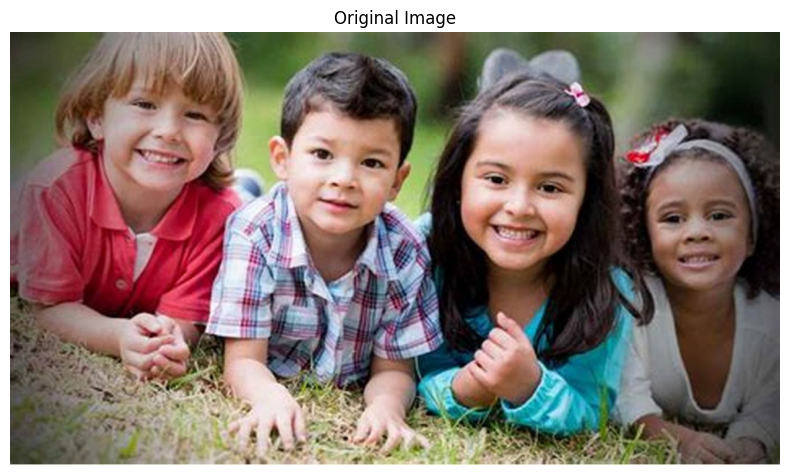

In [18]:
# اكتب اسم صورة الكاميرا هنا، أو اتركه فارغًا لاختيار صورة الاختبار.
SELECTED_IMAGE_NAME = 'children.jpeg'

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
elif sample_face_name in uploaded_images:
    selected_name = sample_face_name
else:
    selected_name = next(iter(uploaded_images))

selected_image = face_resize_max_width(
    uploaded_images[selected_name], 1000
)

print('Selected image:', selected_name)
print('Shape:', selected_image.shape)
show_comparison({'Original Image': selected_image}, columns=1, figure_width=8)

## 7. تنفيذ اكتشاف الوجه والعينين

Faces detected: 3
Eyes detected: 6


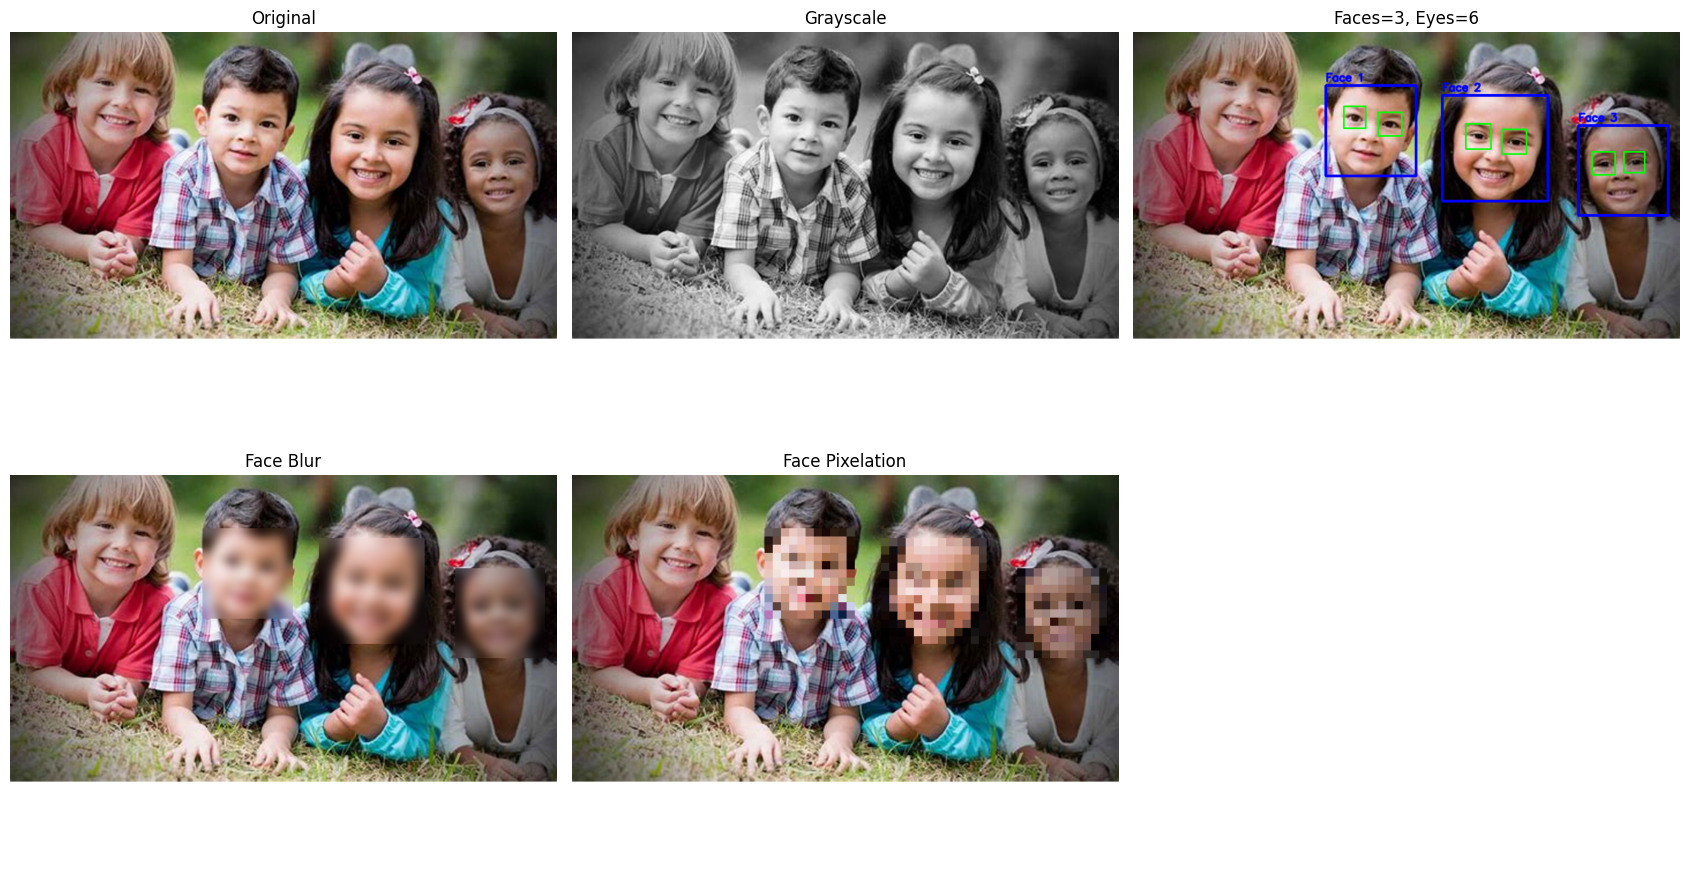

In [21]:
annotated_image, face_count, eye_count, detections, gray_image = (
    detect_faces_and_eyes(
        selected_image,
        face_scale_factor=1.2,
        face_min_neighbors=5,
        minimum_face_size=30,
        eye_scale_factor=1.15,
        eye_min_neighbors=5
    )
)
blurred_faces = anonymize_faces(
    selected_image, detections, method='blur'
)
pixelated_faces = anonymize_faces(
    selected_image, detections, method='pixelate'
)

print('Faces detected:', face_count)
print('Eyes detected:', eye_count)

show_comparison(
    {
        'Original': selected_image,
        'Grayscale': gray_image,
        f'Faces={face_count}, Eyes={eye_count}': annotated_image,
        'Face Blur': blurred_faces,
        'Face Pixelation': pixelated_faces
    },
    columns=3,
    figure_width=17
)

## 8. لماذا نبحث عن العين داخل ROI الوجه؟

بعد اكتشاف الوجه نأخذ من الصورة:

```python
roi_gray = gray[y:y+h, x:x+w]
```

ثم نبحث عن العين داخل هذه المنطقة فقط. هذا يقلل مساحة البحث ويرفع السرعة ويقلل اكتشاف أشياء خارج الوجه على أنها عيون. وفي هذا الدفتر قُيّد البحث بالجزء العلوي من الوجه لأن العينين لا تكونان عادة في الجزء السفلي.

## 9. أداة تفاعلية لضبط معاملات الكشف

In [22]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_face_detection(
    scale_factor=1.2,
    min_neighbors=5,
    minimum_face_size=30,
    eye_min_neighbors=5,
    detect_eyes=True,
    equalize_histogram=True
):
    result, faces, eyes, _, _ = detect_faces_and_eyes(
        selected_image,
        face_scale_factor=scale_factor,
        face_min_neighbors=min_neighbors,
        minimum_face_size=minimum_face_size,
        eye_min_neighbors=eye_min_neighbors,
        detect_eyes=detect_eyes,
        equalize_histogram=equalize_histogram
    )
    show_comparison(
        {
            'Original': selected_image,
            f'Faces={faces}, Eyes={eyes}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    face_controls = widgets.interactive(
        interactive_face_detection,
        scale_factor=widgets.FloatSlider(
            value=1.2, min=1.05, max=1.5, step=0.05,
            description='Scale'
        ),
        min_neighbors=widgets.IntSlider(
            value=5, min=1, max=12, step=1,
            description='Neighbors'
        ),
        minimum_face_size=widgets.IntSlider(
            value=30, min=20, max=200, step=10,
            description='Min size'
        ),
        eye_min_neighbors=widgets.IntSlider(
            value=5, min=1, max=12, step=1,
            description='Eye N'
        ),
        detect_eyes=widgets.Checkbox(
            value=True, description='Detect eyes'
        ),
        equalize_histogram=widgets.Checkbox(
            value=True, description='Equalize'
        )
    )
    display(face_controls)
else:
    interactive_face_detection()

interactive(children=(FloatSlider(value=1.2, description='Scale', max=1.5, min=1.05, step=0.05), IntSlider(val…

## 10. مقارنة نموذج العين العادي ونموذج النظارات

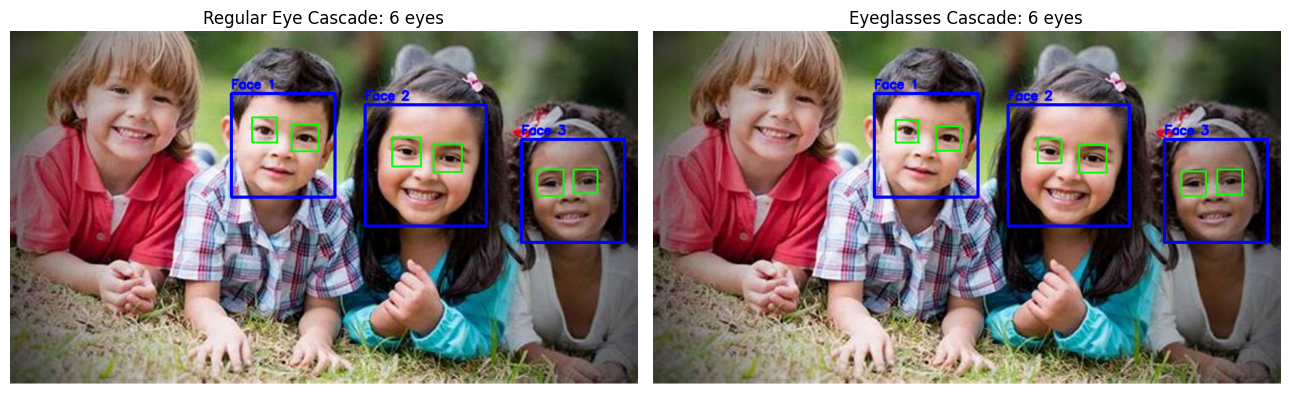

In [23]:
regular_eye_detector = cv2.CascadeClassifier(
    str(FACE_CASCADE_MODELS_DIR / 'haarcascade_eye.xml')
)
glasses_eye_detector = cv2.CascadeClassifier(
    str(FACE_CASCADE_MODELS_DIR / 'haarcascade_eye_tree_eyeglasses.xml')
)

regular_result, regular_faces, regular_eyes, _, _ = (
    detect_faces_and_eyes(
        selected_image,
        eye_detector=regular_eye_detector
    )
)
glasses_result, glasses_faces, glasses_eyes, _, _ = (
    detect_faces_and_eyes(
        selected_image,
        eye_detector=glasses_eye_detector
    )
)

show_comparison(
    {
        f'Regular Eye Cascade: {regular_eyes} eyes': regular_result,
        f'Eyeglasses Cascade: {glasses_eyes} eyes': glasses_result
    },
    columns=2,
    figure_width=13
)

## 11. معالجة جميع الصور وحفظ النتائج

In [24]:
image_report = []
saved_image_files = []

for file_name, source_image in uploaded_images.items():
    source_image = face_resize_max_width(source_image, 1400)
    annotated, faces, eyes, source_detections, source_gray = (
        detect_faces_and_eyes(source_image)
    )
    anonymized = anonymize_faces(
        source_image, source_detections, method='blur'
    )

    stem = Path(file_name).stem
    image_directory = FACE_IMAGE_OUTPUT_DIR / stem
    image_directory.mkdir(parents=True, exist_ok=True)

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_faces_eyes.png': annotated,
        '03_faces_blurred.png': anonymized
    }

    for output_name, result in results.items():
        output_path = image_directory / output_name
        if not cv2.imwrite(str(output_path), result):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_image_files.append(output_path)

    for face_index, detection in enumerate(source_detections, start=1):
        x, y, width, height = detection['face_box']
        face_crop = source_image[y:y + height, x:x + width]
        crop_path = image_directory / f'face_{face_index:02d}.png'
        if face_crop.size > 0 and cv2.imwrite(str(crop_path), face_crop):
            saved_image_files.append(crop_path)

    image_report.append({
        'file_name': file_name,
        'faces': faces,
        'eyes': eyes
    })

report_path = FACE_IMAGE_OUTPUT_DIR / 'face_eye_detection_report.csv'
with report_path.open('w', newline='', encoding='utf-8-sig') as report_file:
    writer = csv.DictWriter(
        report_file,
        fieldnames=['file_name', 'faces', 'eyes']
    )
    writer.writeheader()
    writer.writerows(image_report)

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_image_files)} ملف صورة.')
print('CSV report:', report_path)
for row in image_report:
    print(
        f"- {row['file_name']}: "
        f"faces={row['faces']}, eyes={row['eyes']}"
    )

تمت معالجة 9 صورة.
تم حفظ 47 ملف صورة.
CSV report: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/08_Face_Eye_Detection/face_eye_detection_report.csv
- R.jpeg: faces=1, eyes=2
- balloons.jpg: faces=0, eyes=0
- camera_photo_20260917_225311.jpg: faces=1, eyes=2
- camera_photo_20260917_225540.jpg: faces=1, eyes=2
- camera_photo_20260917_232608.jpg: faces=1, eyes=2
- children (1).jpeg: faces=3, eyes=6
- children.jpeg: faces=3, eyes=6
- coins.jpg: faces=0, eyes=0
- face_test_grace_hopper.jpg: faces=1, eyes=1


## 12. اكتشاف الوجوه والعيون في الفيديو

اترك `PROCESS_VIDEO = False` أثناء تشغيل الدفتر لأول مرة. لمعالجة فيديو صالح موجود في `02_Data/Videos/Input` غيّره إلى `True`، ثم اختر اسم الفيديو أو اترك الاسم فارغًا لاختيار أول فيديو صالح.

يمكن استخدام `DETECT_EVERY_N_FRAMES = 2` لزيادة السرعة؛ سيعاد استخدام آخر كشف في الإطار التالي.

In [25]:
SUPPORTED_VIDEO_EXTENSIONS = {
    '.mp4', '.avi', '.mov', '.mkv', '.webm', '.m4v'
}


def face_valid_video_paths(directory):
    valid_paths = []
    for path in sorted(directory.iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_VIDEO_EXTENSIONS
        ):
            continue
        capture = cv2.VideoCapture(str(path))
        success, frame = capture.read()
        capture.release()
        if success and frame is not None:
            valid_paths.append(path)
        else:
            print('تم تجاهل فيديو غير صالح:', path.name)
    return valid_paths


def draw_detections(image, detections):
    result = image.copy()
    for face_index, detection in enumerate(detections, start=1):
        x, y, width, height = detection['face_box']
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (255, 0, 0), 3
        )
        cv2.putText(
            result, f'Face {face_index}',
            (x, max(22, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (255, 0, 0), 2, cv2.LINE_AA
        )
        for ex, ey, ew, eh in detection['eye_boxes']:
            cv2.rectangle(
                result, (ex, ey), (ex + ew, ey + eh),
                (0, 255, 0), 2
            )
    return result


def process_face_video(
    input_path,
    output_path,
    maximum_width=640,
    maximum_seconds=None,
    detect_every_n_frames=1
):
    capture = cv2.VideoCapture(str(input_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {input_path}')

    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if fps <= 0:
        fps = 25.0
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    maximum_frames = None
    if maximum_seconds is not None and float(maximum_seconds) > 0:
        maximum_frames = int(float(maximum_seconds) * fps)

    success, frame = capture.read()
    if not success or frame is None:
        capture.release()
        raise ValueError('لا يحتوي الفيديو على إطار صالح.')

    frame = face_resize_max_width(frame, maximum_width)
    frame_height, frame_width = frame.shape[:2]
    even_width = frame_width - frame_width % 2
    even_height = frame_height - frame_height % 2
    frame = frame[:even_height, :even_width]

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*'mp4v'),
        fps,
        (even_width, even_height)
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError('تعذر إنشاء فيديو النتيجة.')

    frame_index = 0
    latest_detections = []
    total_face_detections = 0
    start_time = time.perf_counter()

    while success and frame is not None:
        if maximum_frames is not None and frame_index >= maximum_frames:
            break

        frame = face_resize_max_width(frame, maximum_width)
        frame = frame[:even_height, :even_width]

        if frame_index % max(1, int(detect_every_n_frames)) == 0:
            _, faces, _, latest_detections, _ = detect_faces_and_eyes(
                frame
            )
            total_face_detections += faces

        annotated_frame = draw_detections(frame, latest_detections)
        writer.write(annotated_frame)
        frame_index += 1

        if frame_index % 30 == 0:
            if total_frames > 0:
                progress = min(100, 100 * frame_index / total_frames)
                print(
                    f'Processed {frame_index}/{total_frames} '
                    f'frames ({progress:.1f}%)'
                )
            else:
                print('Processed frames:', frame_index)

        success, frame = capture.read()

    capture.release()
    writer.release()

    elapsed = time.perf_counter() - start_time
    speed = frame_index / elapsed if elapsed > 0 else 0.0
    return {
        'frames': frame_index,
        'elapsed_seconds': elapsed,
        'processing_fps': speed,
        'face_detections': total_face_detections
    }


def face_finalize_video(silent_path, original_path, final_path):
    ffmpeg_path = shutil.which('ffmpeg')
    if ffmpeg_path is None:
        shutil.copy2(silent_path, final_path)
        return False

    command = [
        ffmpeg_path, '-y',
        '-i', str(silent_path),
        '-i', str(original_path),
        '-map', '0:v:0', '-map', '1:a?',
        '-c:v', 'libx264', '-preset', 'fast', '-crf', '23',
        '-pix_fmt', 'yuv420p',
        '-c:a', 'aac', '-b:a', '128k',
        '-shortest', '-movflags', '+faststart',
        str(final_path)
    ]
    try:
        subprocess.run(
            command, check=True,
            stdout=subprocess.PIPE, stderr=subprocess.PIPE
        )
        return True
    except subprocess.CalledProcessError:
        shutil.copy2(silent_path, final_path)
        return False

In [26]:
PROCESS_VIDEO = False
SELECTED_VIDEO_NAME = ''
MAX_VIDEO_SECONDS = 20
VIDEO_OUTPUT_WIDTH = 640
DETECT_EVERY_N_FRAMES = 1

available_videos = face_valid_video_paths(FACE_VIDEO_INPUT_DIR)

if PROCESS_VIDEO:
    if not available_videos:
        raise ValueError(
            'لا يوجد فيديو صالح. أضف MP4 إلى مجلد Videos/Input.'
        )

    video_by_name = {path.name: path for path in available_videos}
    if SELECTED_VIDEO_NAME:
        if SELECTED_VIDEO_NAME not in video_by_name:
            raise ValueError('اسم الفيديو المحدد غير موجود.')
        selected_video_path = video_by_name[SELECTED_VIDEO_NAME]
    else:
        selected_video_path = available_videos[0]

    temporary_output = (
        FACE_VIDEO_OUTPUT_DIR
        / f'{selected_video_path.stem}_faces_eyes_opencv.mp4'
    )
    final_output = (
        FACE_VIDEO_OUTPUT_DIR
        / f'{selected_video_path.stem}_faces_eyes.mp4'
    )

    video_statistics = process_face_video(
        selected_video_path,
        temporary_output,
        maximum_width=VIDEO_OUTPUT_WIDTH,
        maximum_seconds=MAX_VIDEO_SECONDS,
        detect_every_n_frames=DETECT_EVERY_N_FRAMES
    )
    converted = face_finalize_video(
        temporary_output, selected_video_path, final_output
    )

    print('Input video:', selected_video_path)
    print('Output video:', final_output)
    print('Browser-compatible conversion:', converted)
    print('Frames:', video_statistics['frames'])
    print(
        'Processing FPS:',
        f"{video_statistics['processing_fps']:.2f}"
    )
    print(
        'Total face detections:',
        video_statistics['face_detections']
    )
else:
    print('معالجة الفيديو معطلة. غيّر PROCESS_VIDEO إلى True عند الحاجة.')
    print('Valid videos found:', len(available_videos))

معالجة الفيديو معطلة. غيّر PROCESS_VIDEO إلى True عند الحاجة.
Valid videos found: 3


## 13. تطبيق الكشف على صورة الكاميرا

لا تحتاج إلى فتح الكاميرا من جديد هنا. الصورة التي التقطتها في الدفتر 07 محفوظة داخل `02_Data/Images/Input`، ولذلك ستظهر تلقائيًا ضمن `uploaded_images`.

ضع اسمها في:

```python
SELECTED_IMAGE_NAME = 'camera_photo_YYYYMMDD_HHMMSS.jpg'
```

ثم أعد تنفيذ خلايا اختيار الصورة والكشف. بهذه الطريقة لا نكرر مشاكل اتصال كاميرا Colab، بينما يعمل الكشف الحقيقي المباشر لاحقًا داخل تطبيق Android.

## 14. القيود العملية لـ Haar Cascade

- يعمل أفضل مع الوجه الأمامي والإضاءة الجيدة.
- قد يفشل مع دوران الوجه الكبير أو الإضاءة الضعيفة.
- قد يعطي مستطيلات خاطئة في الخلفيات المعقدة.
- لا يتعرف على هوية الشخص؛ هو يحدد وجود وجه فقط.
- `minNeighbors` الصغير يزيد الحساسية والنتائج الخاطئة.
- YOLO أو نماذج كشف الوجه الحديثة أدق، لكنها أكبر وأكثر استهلاكًا للموارد.

## 15. الربط بتطبيق Android

| Python/Colab | OpenCV Android | الاستخدام |
|---|---|---|
| `cv2.CascadeClassifier` | `CascadeClassifier` | تحميل ملفات XML |
| `detectMultiScale` | `detectMultiScale` | اكتشاف الوجوه والعيون |
| ROI slicing | `Mat.submat` | البحث عن العين داخل الوجه |
| `cv2.rectangle` | `Imgproc.rectangle` | رسم المستطيلات |
| `GaussianBlur` | `Imgproc.GaussianBlur` | إخفاء الوجه |

سنضع ملفات XML داخل `app/src/main/assets/haarcascades/`، ثم ننسخها عند أول تشغيل إلى مساحة التطبيق ونحمّلها. وسيأخذ CameraX كل إطار، يحوله إلى `Mat`، يطبق الكشف، ثم يعرض النتيجة دون إنترنت.

## 16. أسئلة للمناقشة والتقرير

1. لماذا نحول الصورة إلى Grayscale قبل Haar Cascade؟
2. ما فائدة `equalizeHist` قبل الكشف؟
3. لماذا نبحث عن العين داخل ROI الوجه؟
4. ماذا يحدث عند جعل `minNeighbors=1`؟
5. ما أثر زيادة `scaleFactor` على السرعة والدقة؟
6. ما الفرق بين اكتشاف الوجه والتعرف على هوية الشخص؟
7. لماذا نحتاج نموذجًا مختلفًا للعين والنظارات؟
8. ما الفرق بين Haar Cascade وYOLO؟

> بعد التأكد من حفظ النتائج استخدم `Edit → Clear all outputs` لتقليل حجم الدفتر.

**الخطوة التالية:** الدفتر `09_YOLO_Offline_Object_Detection.ipynb` لاكتشاف الأجسام دلاليًا في الصور والفيديو.

---

## القسم المدمج: Offline YOLO Object Detection

> المصدر الأصلي: `09_Offline_YOLO_Object_Detection.ipynb`. تم الحفاظ على مسارات البيانات والمخرجات الأصلية، مع إعادة تسمية بعض المتغيرات/الدوال فقط لمنع التعارض داخل الدفتر الموحّد.


## 09 — Offline Object Detection with YOLO26n

## مشروع VisionStudio لمعالجة الصور والرؤية الحاسوبية

هذا الدفتر يضيف **اكتشاف الأجسام** إلى المشروع باستخدام نموذج `YOLO26n` الخفيف، مع حفظ النموذج في Google Drive ليعمل لاحقًا دون تنزيل متكرر.

النموذج الأساسي:

```text
yolo26n.pt
```

النموذج الاحتياطي الاختياري للمقارنة:

```text
yolov8n.pt
```

> المقصود بالعمل Offline هو أن التطبيق النهائي سيحتوي على النموذج المحوّل إلى LiteRT/TFLite داخل ملف APK، ولن يحتاج إلى الإنترنت أثناء الاستخدام.


## أهداف الدفتر

بنهاية هذا الدفتر سنتمكن من:

1. تجهيز مكتبة Ultralytics داخل Google Colab.
2. تنزيل `YOLO26n` مرة واحدة فقط وحفظه في Google Drive.
3. إدخال صورة من المجلد أو رفع صورة جديدة عند الحاجة.
4. اكتشاف الأجسام وعرض الصنف والثقة والمربع المحيط.
5. حفظ الصورة الناتجة وقص كل جسم مكتشف.
6. معالجة مجموعة من الصور وإنشاء تقرير CSV.
7. معالجة فيديو اختياريًا مع تحديد مدة قصوى.
8. مقارنة `YOLO26n` و`YOLOv8n` اختياريًا.
9. تصدير النموذج إلى LiteRT/TFLite تمهيدًا لتطبيق Android.

### إعدادات التنفيذ الآمنة

- تنفيذ الصور مفعّل افتراضيًا.
- مقارنة النموذجين معطلة افتراضيًا لأنها تتطلب تنزيل نموذج إضافي.
- معالجة الفيديو معطلة افتراضيًا.
- تصدير LiteRT معطل افتراضيًا لأنه قد يثبت حزم تصدير كبيرة.


## 1. تجهيز مكتبة Ultralytics

شغّل الخلية التالية في بداية جلسة Colab. تنزيل الحزمة يتم على خادم Colab وليس عبر رفع ملف من جهازك.

إذا كانت المكتبة مثبّتة وتدعم `YOLO26n`، يمكنك لاحقًا جعل `INSTALL_OR_UPDATE_ULTRALYTICS = False` في الجلسة نفسها.

> هذا الدفتر لا يستخدم `CascadeClassifier`، لذلك مشكلة OpenCV 5 التي ظهرت في الدفتر 08 لا تؤثر على اكتشاف YOLO هنا. إذا أردت العودة إلى الدفتر 08 بعد تحديث الحزم، استخدم جلسة Colab جديدة أو ثبّت OpenCV 4.10 كما فعلنا سابقًا.


In [2]:
import importlib.util
import subprocess
import sys

INSTALL_OR_UPDATE_ULTRALYTICS = False

if INSTALL_OR_UPDATE_ULTRALYTICS:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install',
        '--quiet', '--upgrade', 'ultralytics'
    ])
elif importlib.util.find_spec('ultralytics') is None:
    raise ImportError(
        'مكتبة ultralytics غير مثبتة. غيّر '
        'INSTALL_OR_UPDATE_ULTRALYTICS إلى True.'
    )

print('Ultralytics setup completed.')

Ultralytics setup completed.


## 2. استيراد المكتبات وربط Google Drive

يحفظ الدفتر النماذج والنتائج داخل بنية المشروع نفسها، لذلك يمكن لبقية الدفاتر وتطبيق Android استخدام الملفات الناتجة.


In [3]:
from pathlib import Path
from datetime import datetime
import csv
import json
import shutil
import subprocess
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

YOLO_IMAGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
YOLO_VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
YOLO_MODELS_DIR = PROJECT_ROOT / '03_Models/YOLO'
LITERT_MODELS_DIR = PROJECT_ROOT / '03_Models/LiteRT'
YOLO_IMAGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/09_YOLO_Object_Detection'
)
YOLO_VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/09_YOLO_Object_Detection'
)

for directory in [
    YOLO_IMAGE_INPUT_DIR,
    YOLO_VIDEO_INPUT_DIR,
    YOLO_MODELS_DIR,
    LITERT_MODELS_DIR,
    YOLO_IMAGE_OUTPUT_DIR,
    YOLO_VIDEO_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else 'cpu'

print('Running in Colab:', IN_COLAB)
print('Ultralytics:', ultralytics.__version__)
print('OpenCV:', cv2.__version__)
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
print('Project:', PROJECT_ROOT)
print('YOLO models:', YOLO_MODELS_DIR)
print('Image output:', YOLO_IMAGE_OUTPUT_DIR)
print('Video output:', YOLO_VIDEO_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Ultralytics: 8.4.155
OpenCV: 5.0.0
PyTorch: 2.11.0+cu128
Device: 0
Project: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing
YOLO models: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO
Image output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/09_YOLO_Object_Detection
Video output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/09_YOLO_Object_Detection


## 3. إعداد النموذج الأساسي والاحتياطي

الحرف `n` يعني **Nano**، وهي النسخة الأصغر والأنسب للهاتف والمعالجة المباشرة.

عند أول تشغيل فقط:

1. تنزّل Ultralytics ملف النموذج.
2. ينسخه الدفتر إلى `03_Models/YOLO`.
3. في التشغيلات التالية يحمّله من Google Drive دون تنزيله مرة أخرى.


In [ ]:
PRIMARY_MODEL_NAME = 'yolo26n.pt'
FALLBACK_MODEL_NAME = 'yolov8n.pt'

# اجعلها False بعد حفظ النموذج إذا أردت منع أي تنزيل تلقائي.
ALLOW_MODEL_DOWNLOAD = True

PRIMARY_MODEL_PATH = YOLO_MODELS_DIR / PRIMARY_MODEL_NAME
FALLBACK_MODEL_PATH = YOLO_MODELS_DIR / FALLBACK_MODEL_NAME


def load_or_download_yolo(model_name, destination_path, allow_download=True):
    destination_path = Path(destination_path)

    if destination_path.exists():
        print('Loading saved model:', destination_path)
        return YOLO(str(destination_path))

    if not allow_download:
        raise FileNotFoundError(
            f'النموذج غير موجود: {destination_path}. '
            'فعّل ALLOW_MODEL_DOWNLOAD لأول تشغيل.'
        )

    print('Downloading model once:', model_name)
    downloaded_model = YOLO(model_name)

    candidate_paths = [Path.cwd() / model_name]
    checkpoint_path = getattr(downloaded_model, 'ckpt_path', None)
    if checkpoint_path:
        candidate_paths.append(Path(checkpoint_path))

    copied = False
    for candidate in candidate_paths:
        if candidate.is_file():
            shutil.copy2(candidate, destination_path)
            copied = True
            break

    if not copied:
        # تحفظ Ultralytics نسخة checkpoint صالحة إذا تغير مكان التنزيل.
        downloaded_model.save(str(destination_path))

    if not destination_path.exists():
        raise FileNotFoundError(
            'تم تحميل النموذج ولكن تعذر نسخه إلى Google Drive.'
        )

    print('Model saved for offline reuse:', destination_path)
    return YOLO(str(destination_path))


primary_model = load_or_download_yolo(
    PRIMARY_MODEL_NAME,
    PRIMARY_MODEL_PATH,
    allow_download=ALLOW_MODEL_DOWNLOAD
)

print('Primary model is ready:', PRIMARY_MODEL_PATH.name)
print('Number of classes:', len(primary_model.names))


Model saved for offline reuse: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.pt
Primary model is ready: yolo26n.pt
Number of classes: 80


## 4. دوال العرض والمعالجة

يمر كشف الأجسام بالمراحل الآتية:

1. تغيير حجم الصورة وإدخالها إلى النموذج.
2. استخراج المربعات والفئات ودرجات الثقة.
3. حذف النتائج الأقل من `CONFIDENCE_THRESHOLD`.
4. استخدام IoU أثناء NMS للتعامل مع المربعات المتداخلة.
5. رسم النتائج وحفظها.

في Ultralytics تتم مراحل المعالجة اللاحقة تلقائيًا عند استخدام `model.predict()`.


In [4]:
def yolo_to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_images(images, columns=2, figure_width=14):
    items = list(images.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 5),
        squeeze=False
    )

    for axis, (title, image) in zip(axes.ravel(), items):
        axis.imshow(
            yolo_to_rgb(image),
            cmap='gray' if image.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def yolo_resize_max_width(image, maximum_width=1280):
    if maximum_width is None or int(maximum_width) <= 0:
        return image
    height, width = image.shape[:2]
    if width <= int(maximum_width):
        return image
    scale = int(maximum_width) / width
    new_height = max(1, int(round(height * scale)))
    return cv2.resize(
        image,
        (int(maximum_width), new_height),
        interpolation=cv2.INTER_AREA
    )


def result_to_rows(result, source_name=''):
    rows = []
    boxes = result.boxes
    if boxes is None:
        return rows

    xyxy_values = boxes.xyxy.detach().cpu().numpy()
    confidence_values = boxes.conf.detach().cpu().numpy()
    class_values = boxes.cls.detach().cpu().numpy().astype(int)

    for index, (box, confidence, class_id) in enumerate(
        zip(xyxy_values, confidence_values, class_values),
        start=1
    ):
        x1, y1, x2, y2 = [float(value) for value in box]
        rows.append({
            'source': source_name,
            'detection_id': index,
            'class_id': int(class_id),
            'class_name': result.names[int(class_id)],
            'confidence': float(confidence),
            'x1': x1,
            'y1': y1,
            'x2': x2,
            'y2': y2
        })

    return rows


def run_detection(
    model,
    image,
    source_name='',
    confidence=0.25,
    iou=0.70,
    image_size=640,
    classes=None
):
    started = time.perf_counter()
    prediction = model.predict(
        source=image,
        conf=float(confidence),
        iou=float(iou),
        imgsz=int(image_size),
        classes=classes,
        device=DEVICE,
        verbose=False
    )[0]
    elapsed_ms = (time.perf_counter() - started) * 1000
    annotated = prediction.plot()
    rows = result_to_rows(prediction, source_name)
    return prediction, annotated, rows, elapsed_ms

## 5. إدخال الصور

لأن سرعة الرفع لديك محدودة، الإعداد الافتراضي هو قراءة الصور الموجودة مسبقًا في Google Drive.

لرفع صورة جديدة مرة واحدة:

```python
UPLOAD_NEW_IMAGE = True
```

بعد الحفظ أعده إلى `False`. يُفضل أن تكون الصورة JPG وأقل من 2 MB.


In [5]:
UPLOAD_NEW_IMAGE = False
SUPPORTED_IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.tif', '.tiff'
}
LAST_UPLOADED_IMAGE_NAME = ''

if IN_COLAB and UPLOAD_NEW_IMAGE:
    from google.colab import files

    uploaded_files = files.upload()
    for file_name, file_data in uploaded_files.items():
        safe_name = Path(file_name).name
        if Path(safe_name).suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS:
            print('تم تجاهل امتداد غير مدعوم:', safe_name)
            continue

        image_array = np.frombuffer(file_data, dtype=np.uint8)
        uploaded_image = cv2.imdecode(
            image_array, cv2.IMREAD_COLOR
        )
        if uploaded_image is None:
            print('تم تجاهل ملف صورة غير صالح:', safe_name)
            continue

        destination = YOLO_IMAGE_INPUT_DIR / safe_name
        if not cv2.imwrite(str(destination), uploaded_image):
            print('تعذر حفظ الصورة:', safe_name)
            continue

        LAST_UPLOADED_IMAGE_NAME = safe_name
        print('Saved:', destination)

# صورة وجه محلية مرفقة مع Matplotlib لتجنب تنزيل صورة اختبار.
sample_name = 'face_test_grace_hopper.jpg'
sample_path = YOLO_IMAGE_INPUT_DIR / sample_name
if not sample_path.exists():
    try:
        from matplotlib.cbook import get_sample_data
        bundled_sample = Path(
            get_sample_data('grace_hopper.jpg', asfileobj=False)
        )
        shutil.copy2(bundled_sample, sample_path)
        print('Added local test image:', sample_name)
    except Exception as error:
        print('تعذر إضافة صورة الاختبار المحلية:', error)


def valid_image_paths(directory):
    paths = []
    for path in sorted(Path(directory).iterdir()):
        if (
            path.is_file()
            and path.suffix.lower() in SUPPORTED_IMAGE_EXTENSIONS
        ):
            image = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if image is not None:
                paths.append(path)
            else:
                print('تم تجاهل صورة غير صالحة:', path.name)
    return paths


available_image_paths = valid_image_paths(YOLO_IMAGE_INPUT_DIR)
if not available_image_paths:
    raise ValueError(
        'لا توجد صورة صالحة داخل 02_Data/Images/Input.'
    )

print('Available images:', len(available_image_paths))
for path in available_image_paths:
    print('-', path.name)

Available images: 9
- R.jpeg
- balloons.jpg
- camera_photo_20260917_225311.jpg
- camera_photo_20260917_225540.jpg
- camera_photo_20260917_232608.jpg
- children (1).jpeg
- children.jpeg
- coins.jpg
- face_test_grace_hopper.jpg


## 6. اختيار صورة وتشغيل YOLO26n

يمكنك كتابة اسم صورة موجودة داخل مجلد الإدخال. عند ترك الاسم فارغًا سيستخدم الدفتر آخر صورة رفعتها، أو صورة الاختبار المحلية.


Selected image: children.jpeg
Shape: (720, 1280, 3)


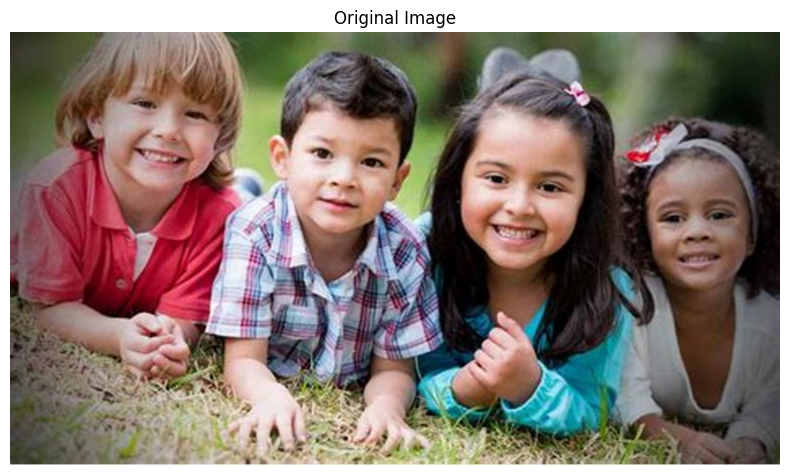

In [6]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
# SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME
SELECTED_IMAGE_NAME = 'children.jpeg'

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)

In [ ]:
UPLOAD_NEW_IMAGE = False
SUPPORTED_IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.tif', '.tiff'
}
LAST_UPLOADED_IMAGE_NAME = 'children.jpeg'

if IN_COLAB and UPLOAD_NEW_IMAGE:
    from google.colab import files

    uploaded_files = files.upload()
    for file_name, file_data in uploaded_files.items():
        safe_name = Path(file_name).name
        if Path(safe_name).suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS:
            print('تم تجاهل امتداد غير مدعوم:', safe_name)
            continue

        image_array = np.frombuffer(file_data, dtype=np.uint8)
        uploaded_image = cv2.imdecode(
            image_array, cv2.IMREAD_COLOR
        )
        if uploaded_image is None:
            print('تم تجاهل ملف صورة غير صالح:', safe_name)
            continue

        destination = YOLO_IMAGE_INPUT_DIR / safe_name
        if not cv2.imwrite(str(destination), uploaded_image):
            print('تعذر حفظ الصورة:', safe_name)
            continue

        LAST_UPLOADED_IMAGE_NAME = safe_name
        print('Saved:', destination)

# صورة وجه محلية مرفقة مع Matplotlib لتجنب تنزيل صورة اختبار.
sample_name = 'face_test_grace_hopper.jpg'
sample_path = YOLO_IMAGE_INPUT_DIR / sample_name
if not sample_path.exists():
    try:
        from matplotlib.cbook import get_sample_data
        bundled_sample = Path(
            get_sample_data('grace_hopper.jpg', asfileobj=False)
        )
        shutil.copy2(bundled_sample, sample_path)
        print('Added local test image:', sample_name)
    except Exception as error:
        print('تعذر إضافة صورة الاختبار المحلية:', error)


def valid_image_paths(directory):
    paths = []
    for path in sorted(Path(directory).iterdir()):
        if (
            path.is_file()
            and path.suffix.lower() in SUPPORTED_IMAGE_EXTENSIONS
        ):
            image = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if image is not None:
                paths.append(path)
            else:
                print('تم تجاهل صورة غير صالحة:', path.name)
    return paths


available_image_paths = valid_image_paths(YOLO_IMAGE_INPUT_DIR)
if not available_image_paths:
    raise ValueError(
        'لا توجد صورة صالحة داخل 02_Data/Images/Input.'
    )

print('Available images:', len(available_image_paths))
for path in available_image_paths:
    print('-', path.name)


Available images: 9
- R.jpeg
- balloons.jpg
- camera_photo_20260917_225311.jpg
- camera_photo_20260917_225540.jpg
- camera_photo_20260917_232608.jpg
- children (1).jpeg
- children.jpeg
- coins.jpg
- face_test_grace_hopper.jpg


Selected image: children.jpeg
Shape: (720, 1280, 3)


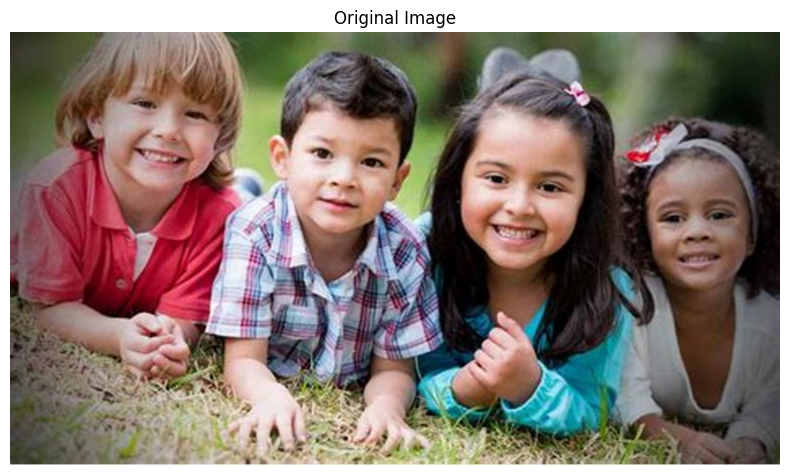

In [ ]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)


Selected image: children.jpeg
Shape: (720, 1280, 3)


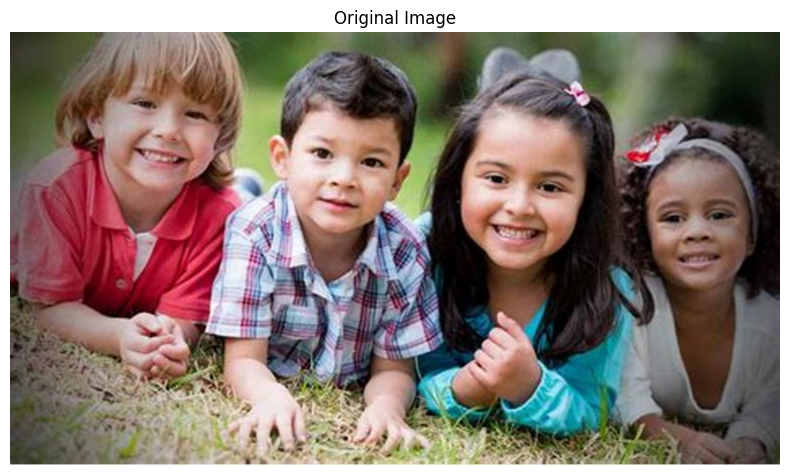

In [ ]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)


Selected image: children.jpeg
Shape: (720, 1280, 3)


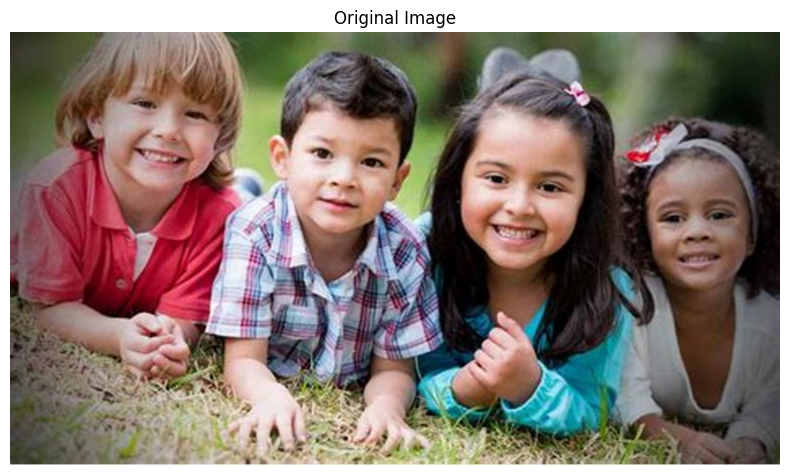

In [ ]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)


Selected image: children.jpeg
Shape: (720, 1280, 3)


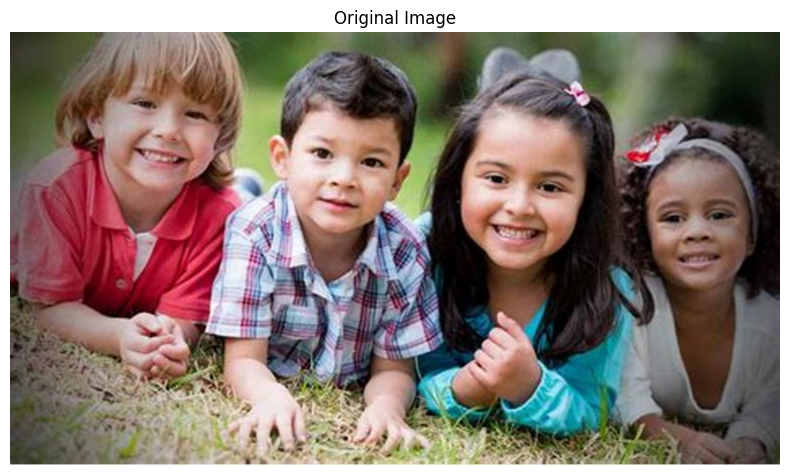

In [ ]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)

Selected image: children.jpeg
Shape: (720, 1280, 3)


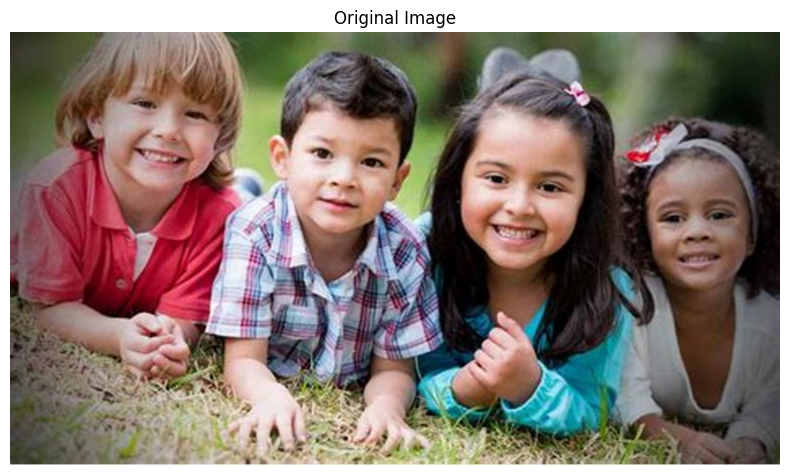

In [ ]:
# مثال: SELECTED_IMAGE_NAME = 'my_photo.jpg'
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME


image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        available_names = ', '.join(image_by_name)
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available_names}'
        )
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif sample_name in image_by_name:
    selected_image_path = image_by_name[sample_name]
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = yolo_resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_images(
    {'Original Image': selected_image},
    columns=1,
    figure_width=8
)


Detected objects: 4
Total prediction call: 17.09 ms
Ultralytics timing: {'preprocess': 2.136079000024438, 'inference': 11.940403000039623, 'postprocess': 1.4947159999110227}


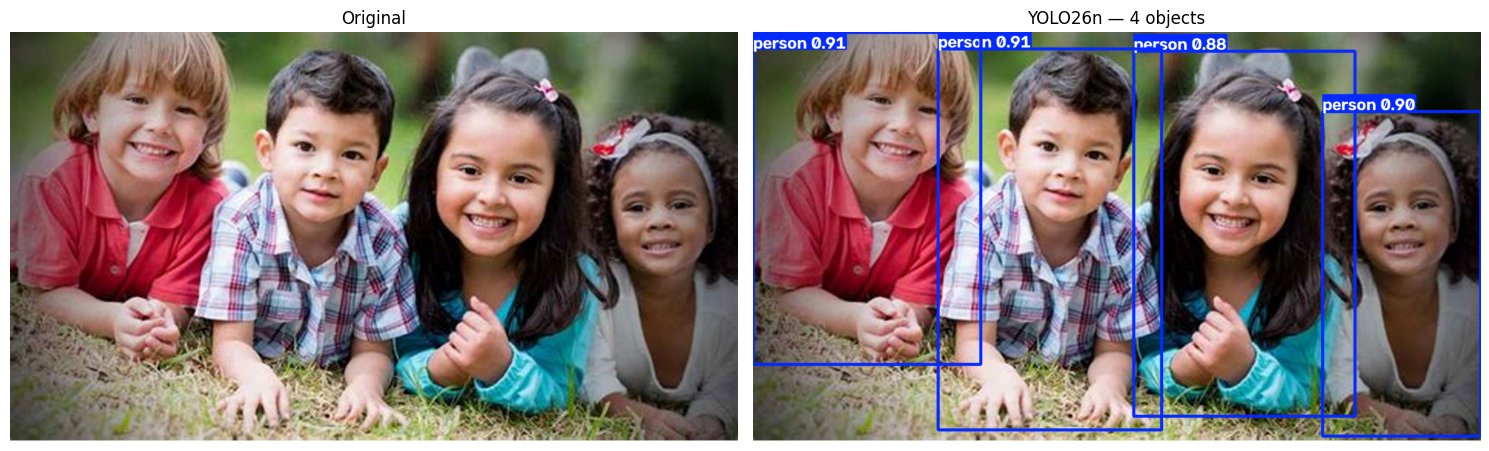

In [ ]:
CONFIDENCE_THRESHOLD = 0.25
IOU_THRESHOLD = 0.70
INFERENCE_IMAGE_SIZE = 640

(
    selected_prediction,
    selected_annotated,
    selected_detection_rows,
    selected_elapsed_ms
) = run_detection(
    primary_model,
    selected_image,
    source_name=selected_image_path.name,
    confidence=CONFIDENCE_THRESHOLD,
    iou=IOU_THRESHOLD,
    image_size=INFERENCE_IMAGE_SIZE
)

print('Detected objects:', len(selected_detection_rows))
print(f'Total prediction call: {selected_elapsed_ms:.2f} ms')
print('Ultralytics timing:', selected_prediction.speed)

show_images(
    {
        'Original': selected_image,
        f'YOLO26n — {len(selected_detection_rows)} objects': (
            selected_annotated
        )
    },
    columns=2,
    figure_width=15
)


## 7. جدول الأجسام المكتشفة

كل صف يحتوي على:

- اسم الفئة.
- درجة الثقة.
- إحداثيات المربع `(x1, y1, x2, y2)`.

درجة الثقة تقع بين 0 و1. رفع العتبة يقلل النتائج الضعيفة، لكنه قد يخفي بعض الأجسام الصحيحة.


In [ ]:
selected_detections_df = pd.DataFrame(selected_detection_rows)

if selected_detections_df.empty:
    print('لم يكتشف النموذج أجسامًا بهذه الإعدادات.')
else:
    display_columns = [
        'detection_id', 'class_name', 'confidence',
        'x1', 'y1', 'x2', 'y2'
    ]
    display(
        selected_detections_df[display_columns].round(3)
    )

    print('\nCounts by class:')
    display(
        selected_detections_df['class_name']
        .value_counts()
        .rename_axis('class_name')
        .reset_index(name='count')
    )


,detection_id,class_name,confidence,x1,y1,x2,y2
0,1,person,0.915,0.627,2.525,400.705,585.060
1,2,person,0.915,325.338,31.029,718.255,700.807
2,3,person,0.904,1001.378,141.982,1279.439,711.670
3,4,person,0.875,669.570,35.995,1058.254,676.576



Counts by class:


,class_name,count
0,person,4


## 8. حفظ الصورة والجدول وقص الأجسام

سيحفظ الدفتر:

- الصورة الأصلية.
- الصورة التي تحتوي على مربعات الكشف.
- ملف CSV.
- صورة منفصلة لكل جسم مكتشف.


In [ ]:
selected_output_directory = (
    YOLO_IMAGE_OUTPUT_DIR / selected_image_path.stem
)
selected_output_directory.mkdir(parents=True, exist_ok=True)

original_output_path = (
    selected_output_directory / '00_original.jpg'
)
annotated_output_path = (
    selected_output_directory / '01_yolo26n_detected.jpg'
)
detections_csv_path = (
    selected_output_directory / 'detections.csv'
)

cv2.imwrite(str(original_output_path), selected_image)
cv2.imwrite(str(annotated_output_path), selected_annotated)
selected_detections_df.to_csv(
    detections_csv_path,
    index=False,
    encoding='utf-8-sig'
)

saved_crops = []
image_height, image_width = selected_image.shape[:2]

for row in selected_detection_rows:
    x1 = max(0, min(image_width, int(round(row['x1']))))
    y1 = max(0, min(image_height, int(round(row['y1']))))
    x2 = max(0, min(image_width, int(round(row['x2']))))
    y2 = max(0, min(image_height, int(round(row['y2']))))

    crop = selected_image[y1:y2, x1:x2]
    if crop.size == 0:
        continue

    safe_class_name = ''.join(
        character if character.isalnum() else '_'
        for character in row['class_name']
    )
    crop_path = selected_output_directory / (
        f"object_{row['detection_id']:02d}_"
        f"{safe_class_name}.jpg"
    )
    if cv2.imwrite(str(crop_path), crop):
        saved_crops.append(crop_path)

print('Original:', original_output_path)
print('Annotated:', annotated_output_path)
print('CSV:', detections_csv_path)
print('Saved object crops:', len(saved_crops))


Original: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/09_YOLO_Object_Detection/children/00_original.jpg
Annotated: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/09_YOLO_Object_Detection/children/01_yolo26n_detected.jpg
CSV: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/09_YOLO_Object_Detection/children/detections.csv
Saved object crops: 4


## 9. التحكم التفاعلي في Confidence وIoU

استخدم أشرطة التحكم لملاحظة تأثير العتبات. لا تجعل `Confidence` منخفضة جدًا لأن ذلك يزيد الاكتشافات الخاطئة.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False


def interactive_yolo_detection(confidence=0.25, iou=0.70):
    _, annotated, rows, elapsed_ms = run_detection(
        primary_model,
        selected_image,
        source_name=selected_image_path.name,
        confidence=confidence,
        iou=iou,
        image_size=INFERENCE_IMAGE_SIZE
    )
    show_images(
        {
            'Original': selected_image,
            (
                f'Objects={len(rows)}, '
                f'Time={elapsed_ms:.1f} ms'
            ): annotated
        },
        columns=2,
        figure_width=14
    )


if WIDGETS_AVAILABLE:
    yolo_controls = widgets.interactive(
        interactive_yolo_detection,
        confidence=widgets.FloatSlider(
            value=0.25,
            min=0.05,
            max=0.90,
            step=0.05,
            description='Confidence',
            continuous_update=False
        ),
        iou=widgets.FloatSlider(
            value=0.70,
            min=0.10,
            max=0.90,
            step=0.05,
            description='IoU',
            continuous_update=False
        )
    )
    display(yolo_controls)
else:
    print('ipywidgets غير متاحة؛ تم تجاوز التحكم التفاعلي.')


interactive(children=(FloatSlider(value=0.25, continuous_update=False, description='Confidence', max=0.9, min=…

## 10. معالجة جميع الصور وإنشاء تقرير

هذه الخلية تمر على الصور الموجودة مسبقًا في مجلد الإدخال، وتحفظ نسخة مكتشفة لكل صورة مع تقرير CSV شامل.


In [ ]:
PROCESS_ALL_IMAGES = True
MAX_BATCH_IMAGES = 30

batch_report_rows = []

if PROCESS_ALL_IMAGES:
    selected_batch_paths = available_image_paths[:MAX_BATCH_IMAGES]

    for image_index, image_path in enumerate(
        selected_batch_paths,
        start=1
    ):
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        image = yolo_resize_max_width(image, 1280)

        _, annotated, rows, elapsed_ms = run_detection(
            primary_model,
            image,
            source_name=image_path.name,
            confidence=CONFIDENCE_THRESHOLD,
            iou=IOU_THRESHOLD,
            image_size=INFERENCE_IMAGE_SIZE
        )

        output_path = YOLO_IMAGE_OUTPUT_DIR / (
            f'{image_path.stem}_yolo26n.jpg'
        )
        cv2.imwrite(str(output_path), annotated)

        if rows:
            batch_report_rows.extend(rows)
        else:
            batch_report_rows.append({
                'source': image_path.name,
                'detection_id': '',
                'class_id': '',
                'class_name': '',
                'confidence': '',
                'x1': '', 'y1': '', 'x2': '', 'y2': ''
            })

        print(
            f'[{image_index}/{len(selected_batch_paths)}] '
            f'{image_path.name}: {len(rows)} objects, '
            f'{elapsed_ms:.1f} ms'
        )

    batch_report_path = (
        YOLO_IMAGE_OUTPUT_DIR / 'all_images_detection_report.csv'
    )
    pd.DataFrame(batch_report_rows).to_csv(
        batch_report_path,
        index=False,
        encoding='utf-8-sig'
    )

    print('Batch report:', batch_report_path)
else:
    print('Batch processing is disabled.')


[1/9] R.jpeg: 1 objects, 17.5 ms
[2/9] balloons.jpg: 1 objects, 15.9 ms
[3/9] camera_photo_20260917_225311.jpg: 2 objects, 19.0 ms
[4/9] camera_photo_20260917_225540.jpg: 1 objects, 13.4 ms
[5/9] camera_photo_20260917_232608.jpg: 1 objects, 11.9 ms
[6/9] children (1).jpeg: 4 objects, 12.3 ms
[7/9] children.jpeg: 4 objects, 13.9 ms
[8/9] coins.jpg: 6 objects, 13.0 ms
[9/9] face_test_grace_hopper.jpg: 2 objects, 13.1 ms
Batch report: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/09_YOLO_Object_Detection/all_images_detection_report.csv


## 11. مقارنة YOLO26n وYOLOv8n — اختيارية

غيّر `COMPARE_WITH_YOLOV8 = True` إذا أردت تنزيل `YOLOv8n` مرة واحدة ومقارنة النموذجين على الصورة نفسها.

لا نعتمد على الأرقام العامة وحدها؛ هذه المقارنة تساعدنا في قياس النتيجة على صور المشروع الفعلية.


In [ ]:
COMPARE_WITH_YOLOV8 = False

if COMPARE_WITH_YOLOV8:
    fallback_model = load_or_download_yolo(
        FALLBACK_MODEL_NAME,
        FALLBACK_MODEL_PATH,
        allow_download=ALLOW_MODEL_DOWNLOAD
    )

    _, yolo8_annotated, yolo8_rows, yolo8_elapsed_ms = (
        run_detection(
            fallback_model,
            selected_image,
            source_name=selected_image_path.name,
            confidence=CONFIDENCE_THRESHOLD,
            iou=IOU_THRESHOLD,
            image_size=INFERENCE_IMAGE_SIZE
        )
    )

    # إعادة تشغيل YOLO26 بعد الإحماء لقياس أكثر عدلًا.
    _, yolo26_annotated, yolo26_rows, yolo26_elapsed_ms = (
        run_detection(
            primary_model,
            selected_image,
            source_name=selected_image_path.name,
            confidence=CONFIDENCE_THRESHOLD,
            iou=IOU_THRESHOLD,
            image_size=INFERENCE_IMAGE_SIZE
        )
    )

    comparison_df = pd.DataFrame([
        {
            'model': 'YOLO26n',
            'objects': len(yolo26_rows),
            'elapsed_ms': yolo26_elapsed_ms
        },
        {
            'model': 'YOLOv8n',
            'objects': len(yolo8_rows),
            'elapsed_ms': yolo8_elapsed_ms
        }
    ])

    display(comparison_df.round(2))
    show_images(
        {
            'YOLO26n': yolo26_annotated,
            'YOLOv8n': yolo8_annotated
        },
        columns=2,
        figure_width=15
    )

    comparison_path = (
        YOLO_IMAGE_OUTPUT_DIR / 'yolo26n_vs_yolov8n.csv'
    )
    comparison_df.to_csv(
        comparison_path,
        index=False,
        encoding='utf-8-sig'
    )
    print('Comparison saved:', comparison_path)
else:
    print(
        'Model comparison is disabled. '
        'Set COMPARE_WITH_YOLOV8 = True when needed.'
    )


Model comparison is disabled. Set COMPARE_WITH_YOLOV8 = True when needed.


## 12. معالجة الفيديو

الفيديو اختياري لأنه أثقل من الصورة. الإعدادات الافتراضية تحد المعالجة إلى أول 20 ثانية وبعرض 640 بكسل.

ضع فيديو صالحًا داخل:

```text
02_Data/Videos/Input
```

ثم غيّر:

```python
PROCESS_VIDEO = True
```


In [52]:
SUPPORTED_VIDEO_EXTENSIONS = {
    '.mp4', '.avi', '.mov', '.mkv', '.webm', '.m4v'
}


def yolo_valid_video_paths(directory):
    paths = []
    for path in sorted(Path(directory).iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_VIDEO_EXTENSIONS
        ):
            continue

        capture = cv2.VideoCapture(str(path))
        success, frame = capture.read()
        capture.release()

        if success and frame is not None:
            paths.append(path)
        else:
            print('تم تجاهل فيديو غير صالح:', path.name)

    return paths


def process_yolo_video(
    model,
    input_path,
    output_path,
    confidence=0.25,
    iou=0.70,
    image_size=640,
    maximum_width=640,
    maximum_seconds=20
):
    capture = cv2.VideoCapture(str(input_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {input_path}')

    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if fps <= 0:
        fps = 25.0

    maximum_frames = None
    if maximum_seconds and float(maximum_seconds) > 0:
        maximum_frames = int(float(maximum_seconds) * fps)

    success, frame = capture.read()
    if not success or frame is None:
        capture.release()
        raise ValueError('الفيديو لا يحتوي على إطار صالح.')

    frame = yolo_resize_max_width(frame, maximum_width)
    height, width = frame.shape[:2]
    width -= width % 2
    height -= height % 2
    frame = frame[:height, :width]

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*'mp4v'),
        fps,
        (width, height)
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError('تعذر إنشاء ملف الفيديو الناتج.')

    processed_frames = 0
    total_detections = 0
    started = time.perf_counter()

    while success and frame is not None:
        if maximum_frames and processed_frames >= maximum_frames:
            break

        frame = yolo_resize_max_width(frame, maximum_width)
        frame = frame[:height, :width]

        _, annotated, rows, _ = run_detection(
            model,
            frame,
            source_name=Path(input_path).name,
            confidence=confidence,
            iou=iou,
            image_size=image_size
        )

        writer.write(annotated)
        total_detections += len(rows)
        processed_frames += 1

        if processed_frames % 30 == 0:
            print('Processed frames:', processed_frames)

        success, frame = capture.read()

    capture.release()
    writer.release()

    elapsed = time.perf_counter() - started
    return {
        'frames': processed_frames,
        'detections': total_detections,
        'source_fps': fps,
        'processing_fps': (
            processed_frames / elapsed if elapsed > 0 else 0
        )
    }


def yolo_finalize_video(opencv_output, original_video, final_output):
    command = [
        'ffmpeg', '-y',
        '-i', str(opencv_output),
        '-i', str(original_video),
        '-map', '0:v:0',
        '-map', '1:a?',
        '-c:v', 'libx264',
        '-pix_fmt', 'yuv420p',
        '-c:a', 'aac',
        '-shortest',
        str(final_output)
    ]

    completed = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if completed.returncode == 0 and Path(final_output).exists():
        return True

    print('FFmpeg warning:', completed.stderr[-500:])
    shutil.copy2(opencv_output, final_output)
    return False

In [56]:
PROCESS_VIDEO = True
SELECTED_VIDEO_NAME = 'kitten.mp4'
MAX_VIDEO_SECONDS = 10
VIDEO_OUTPUT_WIDTH = 640

available_video_paths = yolo_valid_video_paths(YOLO_VIDEO_INPUT_DIR)

if PROCESS_VIDEO:
    if not available_video_paths:
        raise ValueError(
            'لا يوجد فيديو صالح داخل 02_Data/Videos/Input.'
        )

    video_by_name = {
        path.name: path for path in available_video_paths
    }

    if SELECTED_VIDEO_NAME:
        if SELECTED_VIDEO_NAME not in video_by_name:
            raise ValueError('اسم الفيديو المحدد غير موجود.')
        selected_video_path = video_by_name[SELECTED_VIDEO_NAME]
    else:
        selected_video_path = available_video_paths[0]

    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    temporary_video_path = YOLO_VIDEO_OUTPUT_DIR / (
        f'{selected_video_path.stem}_yolo26n_temp_{timestamp}.mp4'
    )
    final_video_path = YOLO_VIDEO_OUTPUT_DIR / (
        f'{selected_video_path.stem}_yolo26n_{timestamp}.mp4'
    )

    video_statistics = process_yolo_video(
        primary_model,
        selected_video_path,
        temporary_video_path,
        confidence=CONFIDENCE_THRESHOLD,
        iou=IOU_THRESHOLD,
        image_size=INFERENCE_IMAGE_SIZE,
        maximum_width=VIDEO_OUTPUT_WIDTH,
        maximum_seconds=MAX_VIDEO_SECONDS
    )

    ffmpeg_succeeded = yolo_finalize_video(
        temporary_video_path,
        selected_video_path,
        final_video_path
    )

    print('Input:', selected_video_path)
    print('Output:', final_video_path)
    print('Frames:', video_statistics['frames'])
    print('Detections:', video_statistics['detections'])
    print(
        'Processing FPS:',
        f"{video_statistics['processing_fps']:.2f}"
    )
    print('Browser-compatible conversion:', ffmpeg_succeeded)
else:
    print('Video processing is disabled.')
    print('Valid videos found:', len(available_video_paths))

Processed frames: 30
Processed frames: 60
Processed frames: 90
Processed frames: 120
Processed frames: 150
Processed frames: 180
Processed frames: 210
Processed frames: 240
Input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input/kitten.mp4
Output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/09_YOLO_Object_Detection/kitten_yolo26n_20260918_005053.mp4
Frames: 250
Detections: 767
Processing FPS: 38.15
Browser-compatible conversion: True


## 13. تصدير YOLO26n إلى LiteRT/TFLite للأندرويد

هذه الخطوة ليست مطلوبة لتجربة YOLO داخل Colab، لكنها مطلوبة لاحقًا لوضع النموذج داخل APK.

غيّر:

```python
EXPORT_LITERT = True
```

في أول تصدير قد تثبّت Ultralytics حزمًا إضافية على خادم Colab. لا تغلق الصفحة حتى تنتهي الخلية.

خيارات الدقة:

- `None`: ‏FP32، أسهل للاختبار الأول.
- `'w8a32'`: أوزان INT8 مع تفعيل FP32، أصغر ولا يحتاج بيانات معايرة وفق واجهة Ultralytics الحالية.
- `8`: ‏INT8 كامل ويحتاج بيانات معايرة ممثلة للصور.

سنبدأ بـFP32 للتأكد من صحة الدمج، ثم نختبر نسخة مضغوطة لاحقًا على الهاتف.


In [57]:
EXPORT_LITERT = True
EXPORT_INPUT_SIZE = 640
EXPORT_QUANTIZATION = None  # None أو 'w8a32' أو 8


def locate_exported_tflite(export_result, model_stem):
    candidates = []
    result_path = Path(str(export_result))

    if result_path.is_file() and result_path.suffix == '.tflite':
        candidates.append(result_path)
    elif result_path.is_dir():
        candidates.extend(result_path.rglob('*.tflite'))

    candidates.extend(
        Path.cwd().glob(f'**/{model_stem}*.tflite')
    )

    unique_candidates = {
        candidate.resolve(): candidate
        for candidate in candidates
        if candidate.is_file()
    }

    if not unique_candidates:
        raise FileNotFoundError(
            'انتهى التصدير لكن لم يتم العثور على ملف TFLite.'
        )

    return max(
        unique_candidates.values(),
        key=lambda path: path.stat().st_mtime
    )


exported_litert_path = None

if EXPORT_LITERT:
    export_arguments = {
        'format': 'litert',
        'imgsz': EXPORT_INPUT_SIZE,
        'batch': 1,
        'device': 'cpu'
    }

    if EXPORT_QUANTIZATION is not None:
        export_arguments['quantize'] = EXPORT_QUANTIZATION

    print('Export settings:', export_arguments)
    export_result = primary_model.export(**export_arguments)

    discovered_tflite = locate_exported_tflite(
        export_result,
        Path(PRIMARY_MODEL_NAME).stem
    )

    quantization_label = (
        'fp32'
        if EXPORT_QUANTIZATION is None
        else str(EXPORT_QUANTIZATION).replace('"', '')
    )
    exported_litert_path = LITERT_MODELS_DIR / (
        f'yolo26n_{quantization_label}.tflite'
    )
    shutil.copy2(discovered_tflite, exported_litert_path)

    labels_path = LITERT_MODELS_DIR / 'coco_labels.txt'
    model_names = primary_model.names
    if isinstance(model_names, dict):
        ordered_labels = [
            model_names[index] for index in sorted(model_names)
        ]
    else:
        ordered_labels = list(model_names)
    labels_text = '\n'.join(ordered_labels)
    labels_path.write_text(labels_text, encoding='utf-8')

    metadata_path = LITERT_MODELS_DIR / 'yolo26n_metadata.json'
    metadata = {
        'model_family': 'YOLO26',
        'variant': 'yolo26n',
        'task': 'object_detection',
        'input_size': [EXPORT_INPUT_SIZE, EXPORT_INPUT_SIZE],
        'class_count': len(primary_model.names),
        'labels_file': labels_path.name,
        'quantization': quantization_label,
        'offline_android_target': True
    }
    metadata_path.write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding='utf-8'
    )

    print('LiteRT model:', exported_litert_path)
    print('Labels:', labels_path)
    print('Metadata:', metadata_path)
else:
    print(
        'LiteRT export is disabled. '
        'Set EXPORT_LITERT = True when ready.'
    )

Export settings: {'format': 'litert', 'imgsz': 640, 'batch': 1, 'device': 'cpu'}
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.3 MB)
requirements: Ultralytics requirements ['litert-torch>=0.9.0', 'ai-edge-litert>=2.1.4'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 86 packages in 601ms
Prepared 15 packages in 2.23s
Uninstalled 3 packages in 40ms
Installed 15 packages in 160ms
 + ai-edge-litert==2.2.0
 + ai-edge-quantizer==0.9.0
 + backports-strenum==1.3.1
 + fire==0.7.1
 - immutabledict==4.3.1
 + imm

/usr/local/lib/python3.13/dist-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.



LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:02) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (21 outputs left out)

(00:17) [ DONE] LiteRT-Torch Convert (+00:17)

(00:00) [START] Write Model to 
/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite

(00:00) [ DONE] Write Model to 
/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite (+00:00)

LiteRT: export success ✅ 24.7s, saved as '/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite' (9.5 MB)

Export complete (25.5s)
Results saved to /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/YOLO/yolo26n.tflite imgsz=640 data=/home/lq/codes/ultralytics/ultralytics/cfg/datasets/coco.yaml  
Visualize:       https://netron.app
LiteRT model: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/LiteRT/yolo26n_fp32.tflite
Labels: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/LiteRT/coco_labels.txt
Metadata: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/LiteRT/yolo26n_metadata.json


## 14. اختبار تشغيل ملف TFLite

هذه الخلية تفحص النموذج المحوّل وتشغّل استدلالًا واحدًا، ثم تعرض أشكال المدخلات والمخرجات. الهدف هنا التأكد من أن الملف غير تالف قبل نسخه إلى مشروع Android.


In [8]:
TEST_EXPORTED_LITERT =  False


def create_litert_interpreter(model_path):
    try:
        from ai_edge_litert.interpreter import Interpreter
        return Interpreter(model_path=str(model_path))
    except ImportError:
        import tensorflow as tf
        return tf.lite.Interpreter(model_path=str(model_path))


def prepare_litert_input(image, input_detail):
    shape = [int(value) for value in input_detail['shape']]
    dtype = input_detail['dtype']

    if len(shape) != 4:
        raise ValueError(f'شكل إدخال غير متوقع: {shape}')

    channels_last = shape[-1] == 3
    if channels_last:
        target_height, target_width = shape[1], shape[2]
    else:
        target_height, target_width = shape[2], shape[3]

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (target_width, target_height))
    tensor = resized.astype(np.float32) / 255.0

    if not channels_last:
        tensor = np.transpose(tensor, (2, 0, 1))

    tensor = np.expand_dims(tensor, axis=0)

    if np.issubdtype(dtype, np.integer):
        scale, zero_point = input_detail.get(
            'quantization', (0.0, 0)
        )
        if scale and scale > 0:
            tensor = np.round(tensor / scale + zero_point)
        limits = np.iinfo(dtype)
        tensor = np.clip(tensor, limits.min, limits.max)

    return tensor.astype(dtype)


if TEST_EXPORTED_LITERT:
    available_tflite_files = sorted(
        LITERT_MODELS_DIR.glob('*.tflite')
    )
    if not available_tflite_files:
        raise FileNotFoundError(
            'لا يوجد ملف TFLite. نفّذ خلية التصدير أولًا.'
        )

    test_model_path = available_tflite_files[-1]
    interpreter = create_litert_interpreter(test_model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    input_tensor = prepare_litert_input(
        selected_image,
        input_details[0]
    )
    interpreter.set_tensor(
        input_details[0]['index'],
        input_tensor
    )

    started = time.perf_counter()
    interpreter.invoke()
    litert_elapsed_ms = (time.perf_counter() - started) * 1000

    output_shapes = []
    for detail in output_details:
        output_tensor = interpreter.get_tensor(detail['index'])
        output_shapes.append(list(output_tensor.shape))

    print('Tested model:', test_model_path)
    print('Input shape:', list(input_tensor.shape))
    print('Input dtype:', input_tensor.dtype)
    print('Output shapes:', output_shapes)
    print(f'LiteRT invoke time: {litert_elapsed_ms:.2f} ms')
else:
    print(
        'LiteRT test is disabled. '
        'Enable it after exporting the model.'
    )

LiteRT test is disabled. Enable it after exporting the model.


## 15. الربط مع تطبيق Android

بعد نجاح التصدير ستنتقل الملفات التالية إلى مجلد `app/src/main/assets`:

```text
yolo26n_fp32.tflite
coco_labels.txt
yolo26n_metadata.json
```

داخل Android سنستخدم واجهة مستقلة مثل:

```kotlin
interface ObjectDetector {
    fun detect(bitmap: Bitmap): List<Detection>
    fun close()
}
```

وبذلك يمكن استبدال YOLO26 مستقبلًا دون تغيير الكاميرا أو محرر الصور. التنفيذ في التطبيق سيمر بالمراحل الآتية:

1. الحصول على إطار من CameraX أو صورة من الجهاز.
2. تغيير الحجم والتطبيع بما يطابق النموذج.
3. تشغيل LiteRT محليًا.
4. تفسير المخرجات وتطبيق المعالجة اللاحقة المطلوبة.
5. رسم المربعات والفئات على الشاشة.
6. حفظ الصورة أو الفيديو الناتج.

> ملفات النموذج ستكون داخل APK؛ لذلك لن يحتاج المستخدم إلى الإنترنت أثناء الكشف.


## 16. ملاحظات علمية وحدود النموذج

- النموذج المدرّب مسبقًا يعرف فئات COCO فقط، وعددها 80 فئة.
- قد يفشل مع الأجسام الصغيرة أو المظلمة أو المحجوبة.
- قيمة Confidence المرتفعة تقلل النتائج الخاطئة لكنها قد تفوّت أجسامًا صحيحة.
- سرعة Colab لا تمثل سرعة الهاتف؛ يجب قياس FPS داخل APK.
- يجب اختبار FP32 والنسخة المضغوطة على الهاتف قبل اختيار النموذج النهائي.
- إذا احتجنا فئات خاصة بالمشروع، سنجمع بيانات وننفذ Fine-tuning بدل تدريب YOLO من الصفر.
- ترخيص Ultralytics الحالي يتطلب مراجعة شروط AGPL-3.0 أو الترخيص التجاري إذا تحول المشروع مستقبلًا إلى منتج مغلق المصدر؛ أما الاستخدام الأكاديمي فيجب توثيق المصدر والترخيص في التقرير.


## 17. أسئلة المناقشة

1. لماذا اخترنا نسخة Nano بدل النسخ الأكبر؟
2. ما الفرق بين Confidence وIoU؟
3. لماذا نحفظ النموذج في Google Drive؟
4. لماذا لا تكفي سرعة النموذج في Colab للحكم على Android؟
5. ما فائدة تحويل النموذج من PyTorch إلى LiteRT/TFLite؟
6. كيف نجعل التطبيق يعمل دون إنترنت؟
7. ما الفرق بين Object Detection وImage Classification؟
8. لماذا نحافظ على YOLOv8n كخيار احتياطي؟
9. كيف نضيف فئات جديدة لا توجد ضمن COCO؟
10. ما الفائدة من فصل `ObjectDetector` عن واجهة الكاميرا؟


## خلاصة الدفتر 09

أصبح المشروع يدعم:

- اكتشاف 80 فئة جاهزة في الصور.
- عرض المربعات والفئات والثقة.
- قص الأجسام المكتشفة وحفظها.
- إنشاء تقارير CSV.
- معالجة الصور دفعة واحدة.
- معالجة فيديو اختياريًا.
- مقارنة YOLO26n وYOLOv8n اختياريًا.
- تجهيز ملفات LiteRT/TFLite لتطبيق Android Offline.

### الخطوة التالية

الدفتر 10 سيجمع وظائف المعالجة في واجهة تجريبية موحدة قبل الانتقال إلى بناء تطبيق Android.
